# Product Growth Analytics: Funnel and Sensitivity Analysis

**Decision question:** Which product page or funnel stage should receive
the next product investment?

This notebook consumes only governed aggregate extracts. It separates:

1. observed historical behavior;
2. benchmark and lift scenarios; and
3. claims that require a randomized experiment.

No user, session, event, or order identifiers are loaded. Page
opportunity values are non-additive because one session may view more
than one product page.

## 1. Load the latest complete aggregate export

SQL remains the source of truth. Run `make all` or `make extract` before
executing this notebook. The code selects the newest timestamped export
containing every required aggregate file.

In [1]:
%matplotlib inline

from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd()
RESULT_ROOT = ROOT / "data" / "interim" / "query_results"
FIGURE_DIR = ROOT / "notebooks" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_FILES = [
    "01_metric_tree_summary.csv",
    "02_funnel_overall.csv",
    "03_funnel_by_segment.csv",
    "04_page_opportunity.csv",
    "05_checkout_funnel.csv",
    "06_retention_weekly.csv",
    "08_metric_tree_daily.csv",
    "09_retention_date_alignment_diagnostic.csv",
    "10_page_funnel_all.csv",
]
complete_exports = [
    path
    for path in RESULT_ROOT.iterdir()
    if path.is_dir()
    and all((path / filename).is_file() for filename in REQUIRED_FILES)
]
if not complete_exports:
    raise FileNotFoundError(
        "No complete aggregate export found. Run `make extract` first."
    )
EXPORT_DIR = sorted(complete_exports)[-1]

def read_result(filename):
    return pd.read_csv(EXPORT_DIR / filename)

summary = read_result("01_metric_tree_summary.csv").iloc[0]
funnel = read_result("02_funnel_overall.csv")
segments = read_result("03_funnel_by_segment.csv")
page_opportunity = read_result("04_page_opportunity.csv")
checkout = read_result("05_checkout_funnel.csv")
retention = read_result("06_retention_weekly.csv")
daily = read_result("08_metric_tree_daily.csv")
retention_alignment = read_result(
    "09_retention_date_alignment_diagnostic.csv"
)
page_all = read_result("10_page_funnel_all.csv")

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "font.size": 10,
    }
)
NAVY = "#17324D"
BLUE = "#2C7FB8"
TEAL = "#2A9D8F"
ORANGE = "#F4A261"
RED = "#D95F59"
GREY = "#7A8793"

print(f"Aggregate export: {EXPORT_DIR.name}")
print(f"Loaded {len(page_all):,} aggregate PDP rows.")

Aggregate export: 20260731T052813Z
Loaded 553 aggregate PDP rows.


In [2]:
# Hard notebook input contracts.
datasets = {
    "summary": pd.DataFrame([summary]),
    "funnel": funnel,
    "segments": segments,
    "page_opportunity": page_opportunity,
    "checkout": checkout,
    "retention": retention,
    "daily": daily,
    "page_all": page_all,
}
forbidden_identifier_columns = {
    "user_key",
    "session_key",
    "event_timestamp",
    "order_key",
    "transaction_id",
}
for name, frame in datasets.items():
    leaked = forbidden_identifier_columns.intersection(frame.columns)
    assert not leaked, f"{name} contains prohibited identifiers: {leaked}"

assert int(summary["sessions"]) == 360_129
assert funnel["sessions"].astype(int).tolist() == [
    77_020,
    14_380,
    5_187,
    2_491,
]
assert len(page_all) == 553
assert len(page_opportunity) == 191
assert checkout["sessions"].is_monotonic_decreasing
assert retention["retention_week"].between(0, 8).all()

kpis = pd.DataFrame(
    {
        "Metric": [
            "Pseudonymous users",
            "Valid sessions",
            "Clean orders",
            "Revenue",
            "Purchase-session conversion",
            "Average order value",
            "Revenue per session",
        ],
        "Observed": [
            f"{int(summary['pseudonymous_users']):,}",
            f"{int(summary['sessions']):,}",
            f"{int(summary['orders']):,}",
            f"${summary['revenue_usd']:,.0f}",
            f"{summary['purchase_session_conversion_rate']:.2%}",
            f"${summary['average_order_value_usd']:,.2f}",
            f"${summary['revenue_per_session_usd']:,.2f}",
        ],
    }
)
display(kpis)

,Metric,Observed
0,Pseudonymous users,"270,154"
1,Valid sessions,"360,129"
2,Clean orders,"4,436"
3,Revenue,"$306,678"
4,Purchase-session conversion,1.12%
5,Average order value,$69.13
6,Revenue per session,$0.85


## 2. Ordered funnel: where is the observed loss?

The primary funnel requires strict event ordering in the same session.
It is a diagnostic path, not a claim that all purchases follow these
four recorded steps.

,Stage,Sessions,Lost from prior stage,Step conversion
0,view_item,77020,0,100.00%
1,add_to_cart,14380,62640,18.67%
2,begin_checkout,5187,9193,36.07%
3,purchase,2491,2696,48.02%


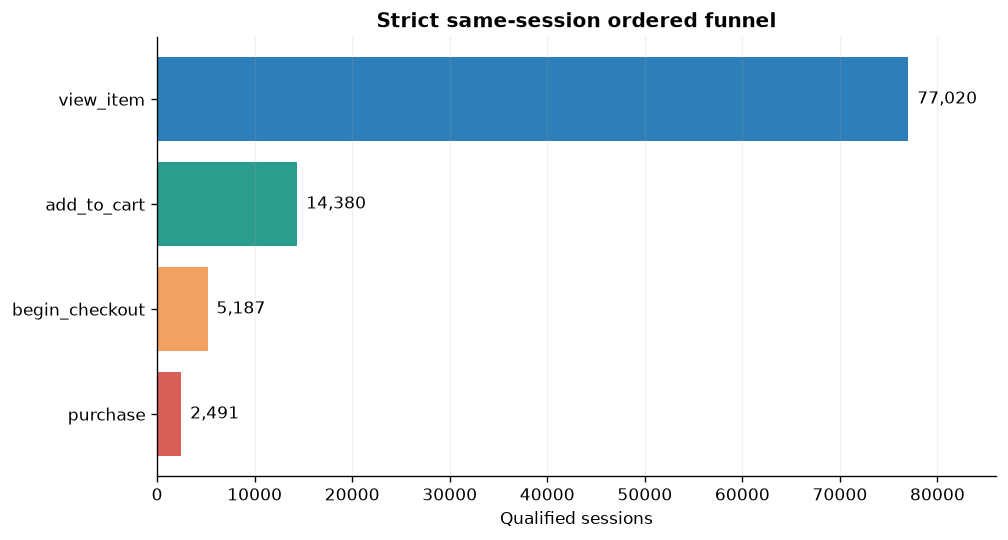

Largest absolute loss: 62,640 sessions before add_to_cart


In [3]:
funnel_view = funnel[
    [
        "stage_name",
        "sessions",
        "step_conversion_rate",
        "lost_sessions_from_prior_stage",
    ]
].copy()
funnel_view["Step conversion"] = funnel_view[
    "step_conversion_rate"
].map(lambda value: f"{value:.2%}")
funnel_view = funnel_view.rename(
    columns={
        "stage_name": "Stage",
        "sessions": "Sessions",
        "lost_sessions_from_prior_stage": "Lost from prior stage",
    }
).drop(columns="step_conversion_rate")
display(funnel_view)

plot_data = funnel.sort_values("stage_index", ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.barh(
    plot_data["stage_name"],
    plot_data["sessions"],
    color=[RED, ORANGE, TEAL, BLUE],
)
ax.set_title("Strict same-session ordered funnel")
ax.set_xlabel("Qualified sessions")
ax.grid(axis="x", alpha=0.18)
for bar, value in zip(bars, plot_data["sessions"]):
    ax.text(
        bar.get_width() + 900,
        bar.get_y() + bar.get_height() / 2,
        f"{int(value):,}",
        va="center",
    )
ax.set_xlim(0, 86_000)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_ordered_funnel.png", bbox_inches="tight")
plt.show()

largest_loss = funnel.loc[
    funnel["lost_sessions_from_prior_stage"].idxmax()
]
print(
    "Largest absolute loss:",
    f"{int(largest_loss['lost_sessions_from_prior_stage']):,}",
    "sessions before",
    largest_loss["stage_name"],
)

## 3. Segment comparisons and difference intervals

Each group rate already includes a 95% Wilson interval. For preselected
two-group comparisons below, the difference interval uses Newcombe's
Wilson-score method. Session observations are treated as independent
for this descriptive calculation; repeated users across sessions remain
a limitation.

In [4]:
Z_95 = 1.959963984540054

def wilson_interval(successes, trials, z=Z_95):
    successes = int(successes)
    trials = int(trials)
    if trials == 0:
        return (np.nan, np.nan)
    proportion = successes / trials
    denominator = 1 + z**2 / trials
    center = (proportion + z**2 / (2 * trials)) / denominator
    half_width = (
        z
        * math.sqrt(
            proportion * (1 - proportion) / trials
            + z**2 / (4 * trials**2)
        )
        / denominator
    )
    return max(0, center - half_width), min(1, center + half_width)

def newcombe_difference(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    lower1, upper1 = wilson_interval(x1, n1)
    lower2, upper2 = wilson_interval(x2, n2)
    difference = p1 - p2
    lower = difference - math.sqrt(
        (p1 - lower1) ** 2 + (upper2 - p2) ** 2
    )
    upper = difference + math.sqrt(
        (upper1 - p1) ** 2 + (p2 - lower2) ** 2
    )
    return difference, max(-1, lower), min(1, upper)

def segment_row(segment_type, segment_value, metric_name):
    selected = segments[
        (segments["segment_type"] == segment_type)
        & (segments["segment_value"] == segment_value)
        & (segments["metric_name"] == metric_name)
    ]
    assert len(selected) == 1
    return selected.iloc[0]

comparison_specs = [
    (
        "Mobile − Desktop",
        ("Device", "mobile"),
        ("Device", "desktop"),
        "purchase_session_conversion",
    ),
    (
        "Mobile − Desktop",
        ("Device", "mobile"),
        ("Device", "desktop"),
        "ordered_view_to_purchase",
    ),
    (
        "Returning − New",
        ("User tenure", "Returning"),
        ("User tenure", "New"),
        "purchase_session_conversion",
    ),
    (
        "Returning − New",
        ("User tenure", "Returning"),
        ("User tenure", "New"),
        "checkout_to_purchase",
    ),
    (
        "Returning − New",
        ("User tenure", "Returning"),
        ("User tenure", "New"),
        "ordered_view_to_purchase",
    ),
]

comparison_rows = []
for label, group1, group2, metric in comparison_specs:
    row1 = segment_row(*group1, metric)
    row2 = segment_row(*group2, metric)
    x1, n1 = int(row1["numerator_sessions"]), int(
        row1["denominator_sessions"]
    )
    x2, n2 = int(row2["numerator_sessions"]), int(
        row2["denominator_sessions"]
    )
    difference, lower, upper = newcombe_difference(x1, n1, x2, n2)
    comparison_rows.append(
        {
            "Comparison": label,
            "Metric": metric,
            "Group 1 rate": x1 / n1,
            "Group 2 rate": x2 / n2,
            "Difference (pp)": difference * 100,
            "95% CI lower (pp)": lower * 100,
            "95% CI upper (pp)": upper * 100,
            "CI excludes zero": lower > 0 or upper < 0,
        }
    )

comparisons = pd.DataFrame(comparison_rows)
formatted_comparisons = comparisons.copy()
for column in ["Group 1 rate", "Group 2 rate"]:
    formatted_comparisons[column] = formatted_comparisons[column].map(
        lambda value: f"{value:.2%}"
    )
for column in [
    "Difference (pp)",
    "95% CI lower (pp)",
    "95% CI upper (pp)",
]:
    formatted_comparisons[column] = formatted_comparisons[column].map(
        lambda value: f"{value:+.2f}"
    )
display(formatted_comparisons)

,Comparison,Metric,Group 1 rate,Group 2 rate,Difference (pp),95% CI lower (pp),95% CI upper (pp),CI excludes zero
0,Mobile − Desktop,purchase_session_conversion,1.15%,1.10%,+0.06,-0.01,+0.13,False
1,Mobile − Desktop,ordered_view_to_purchase,3.37%,3.14%,+0.22,-0.03,+0.48,False
2,Returning − New,purchase_session_conversion,2.55%,0.57%,+1.98,+1.87,+2.08,True
3,Returning − New,checkout_to_purchase,57.09%,38.74%,+18.34,+15.65,+21.00,True
4,Returning − New,ordered_view_to_purchase,6.03%,1.90%,+4.13,+3.81,+4.45,True


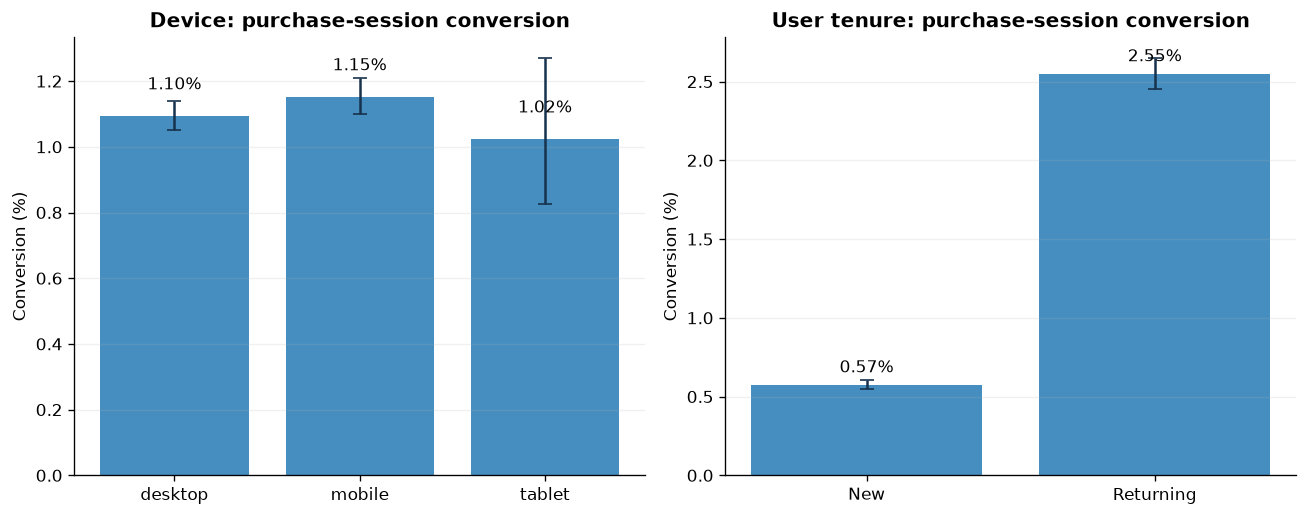

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
panels = [
    ("Device", ["desktop", "mobile", "tablet"]),
    ("User tenure", ["New", "Returning"]),
]
for ax, (segment_type, ordering) in zip(axes, panels):
    frame = segments[
        (segments["segment_type"] == segment_type)
        & (
            segments["metric_name"]
            == "purchase_session_conversion"
        )
    ].set_index("segment_value").loc[ordering].reset_index()
    rates = frame["conversion_rate"] * 100
    lower_errors = (
        frame["conversion_rate"]
        - frame["conversion_rate_ci95_lower"]
    ) * 100
    upper_errors = (
        frame["conversion_rate_ci95_upper"]
        - frame["conversion_rate"]
    ) * 100
    ax.bar(frame["segment_value"], rates, color=BLUE, alpha=0.88)
    ax.errorbar(
        frame["segment_value"],
        rates,
        yerr=[lower_errors, upper_errors],
        fmt="none",
        ecolor=NAVY,
        capsize=4,
    )
    ax.set_title(f"{segment_type}: purchase-session conversion")
    ax.set_ylabel("Conversion (%)")
    ax.grid(axis="y", alpha=0.18)
    for index, value in enumerate(rates):
        ax.text(index, value + 0.08, f"{value:.2f}%", ha="center")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "02_segment_conversion.png",
    bbox_inches="tight",
)
plt.show()

### Channel-quality sensitivity

The channel proxy is not clean attribution. The following sensitivity
compares the all-session baseline with stable named channel groups after
excluding Missing, Conflicting, Obfuscated, and Self-referral buckets.
A large baseline shift is evidence that channel rankings are not
decision-grade.

In [6]:
channel = segments[
    (segments["segment_type"] == "Session channel proxy")
    & (
        segments["metric_name"]
        == "purchase_session_conversion"
    )
].copy()
quality_buckets = {
    "Missing",
    "Conflicting",
    "Obfuscated",
    "Self-referral",
}
stable_channel = channel[
    ~channel["segment_value"].isin(quality_buckets)
]
quality_channel = channel[
    channel["segment_value"].isin(quality_buckets)
]

def pooled_rate(frame):
    successes = int(frame["numerator_sessions"].sum())
    trials = int(frame["denominator_sessions"].sum())
    lower, upper = wilson_interval(successes, trials)
    return successes, trials, successes / trials, lower, upper

channel_sensitivity_rows = []
for label, frame in [
    ("All sessions", channel),
    ("Stable named channels only", stable_channel),
    ("Quality buckets only", quality_channel),
]:
    successes, trials, rate, lower, upper = pooled_rate(frame)
    channel_sensitivity_rows.append(
        {
            "Population": label,
            "Sessions": trials,
            "Purchasing sessions": successes,
            "Conversion": rate,
            "95% CI": f"{lower:.2%}–{upper:.2%}",
        }
    )
channel_sensitivity = pd.DataFrame(channel_sensitivity_rows)
channel_display = channel_sensitivity.copy()
channel_display["Sessions"] = channel_display["Sessions"].map(
    lambda value: f"{value:,}"
)
channel_display["Purchasing sessions"] = channel_display[
    "Purchasing sessions"
].map(lambda value: f"{value:,}")
channel_display["Conversion"] = channel_display["Conversion"].map(
    lambda value: f"{value:.2%}"
)
display(channel_display)

excluded_share = (
    quality_channel["denominator_sessions"].sum()
    / channel["denominator_sessions"].sum()
)
print(
    f"Quality buckets contain {excluded_share:.2%} of sessions; "
    "channel filtering materially changes the conversion baseline."
)

,Population,Sessions,Purchasing sessions,Conversion,95% CI
0,All sessions,"360,129","4,021",1.12%,1.08%–1.15%
1,Stable named channels only,"107,563",543,0.50%,0.46%–0.55%
2,Quality buckets only,"252,566","3,478",1.38%,1.33%–1.42%


Quality buckets contain 70.13% of sessions; channel filtering materially changes the conversion baseline.


## 4. Daily-volume anomaly sensitivity

The source profile flagged four low-volume dates and one high-volume
date. We recompute additive metrics after excluding those five dates.
This is a sensitivity result, not the primary definition.

In [7]:
def to_boolean(series):
    if series.dtype == bool:
        return series
    return series.astype(str).str.lower().eq("true")

anomaly_mask = to_boolean(daily["is_low_volume_date"]) | to_boolean(
    daily["is_high_volume_date"]
)

def aggregate_daily(frame):
    sessions_count = frame["sessions"].sum()
    views = frame["product_view_sessions"].sum()
    adds = frame["ordered_add_to_cart_sessions"].sum()
    checkouts = frame["ordered_checkout_sessions"].sum()
    purchases = frame["ordered_purchase_sessions"].sum()
    purchasing_sessions = frame["purchasing_sessions"].sum()
    orders = frame["orders"].sum()
    revenue = frame["revenue_usd"].sum()
    return {
        "Days": len(frame),
        "Sessions": sessions_count,
        "View → cart": adds / views,
        "Cart → checkout": checkouts / adds,
        "Checkout → purchase": purchases / checkouts,
        "Ordered view → purchase": purchases / views,
        "Purchase-session conversion": (
            purchasing_sessions / sessions_count
        ),
        "AOV": revenue / orders,
        "Revenue/session": revenue / sessions_count,
    }

daily_sensitivity = pd.DataFrame(
    {
        "Full 92-day window": aggregate_daily(daily),
        "Exclude 5 flagged dates": aggregate_daily(
            daily.loc[~anomaly_mask]
        ),
    }
).T
for metric in [
    "View → cart",
    "Cart → checkout",
    "Checkout → purchase",
    "Ordered view → purchase",
    "Purchase-session conversion",
]:
    daily_sensitivity[metric] = daily_sensitivity[metric].map(
        lambda value: f"{value:.2%}"
    )
daily_sensitivity["Sessions"] = daily_sensitivity["Sessions"].map(
    lambda value: f"{int(value):,}"
)
daily_sensitivity["AOV"] = daily_sensitivity["AOV"].map(
    lambda value: f"${value:.2f}"
)
daily_sensitivity["Revenue/session"] = daily_sensitivity[
    "Revenue/session"
].map(lambda value: f"${value:.2f}")
display(daily_sensitivity)

full_purchase_rate = (
    daily["purchasing_sessions"].sum() / daily["sessions"].sum()
)
filtered = daily.loc[~anomaly_mask]
filtered_purchase_rate = (
    filtered["purchasing_sessions"].sum()
    / filtered["sessions"].sum()
)
print(
    "Purchase-session conversion changes by "
    f"{(filtered_purchase_rate - full_purchase_rate) * 10_000:+.2f} "
    "basis points."
)

,Days,Sessions,View → cart,Cart → checkout,Checkout → purchase,Ordered view → purchase,Purchase-session conversion,AOV,Revenue/session
Full 92-day window,92.0000,"360,129",18.67%,36.07%,48.02%,3.23%,1.12%,$69.13,$0.85
Exclude 5 flagged dates,87.0000,"342,261",18.40%,36.18%,48.07%,3.20%,1.13%,$69.32,$0.86


Purchase-session conversion changes by +0.92 basis points.


## 5. PDP threshold and benchmark sensitivity

The governed page rule uses at least 200 session-page views and the
high-traffic-page P75 conversion benchmark. Here we vary:

- minimum page views: 50, 100, 200, 500, 1,000; and
- peer benchmark: exact P50, P75, and P90.

The downstream add-to-purchase rate and AOV remain fixed. Opportunity
estimates are scenarios and cannot be summed across pages.

,Minimum views,Benchmark,Eligible pages,Exposure coverage,Benchmark rate,Top page,Top page orders,Top page revenue
0,50,P50,316,98.6%,2.92%,Super G Unisex Joggers,11.4,$790
1,50,P75,316,98.6%,5.13%,Super G Unisex Joggers,26.1,"$1,804"
2,50,P90,316,98.6%,9.30%,Super G Unisex Joggers,53.8,"$3,716"
3,100,P50,258,96.8%,2.72%,Google Dino Game Tee,10.5,$725
4,100,P75,258,96.8%,4.75%,Super G Unisex Joggers,23.6,"$1,629"
5,100,P90,258,96.8%,13.41%,Super G Unisex Joggers,81.0,"$5,601"
6,200,P50,191,92.6%,2.15%,Google Dino Game Tee,8.1,$562
7,200,P75,191,92.6%,4.42%,Super G Unisex Joggers,21.4,"$1,478"
8,200,P90,191,92.6%,16.91%,Super G Unisex Joggers,104.2,"$7,206"
9,500,P50,102,80.5%,1.20%,Google Dino Game Tee,4.1,$286


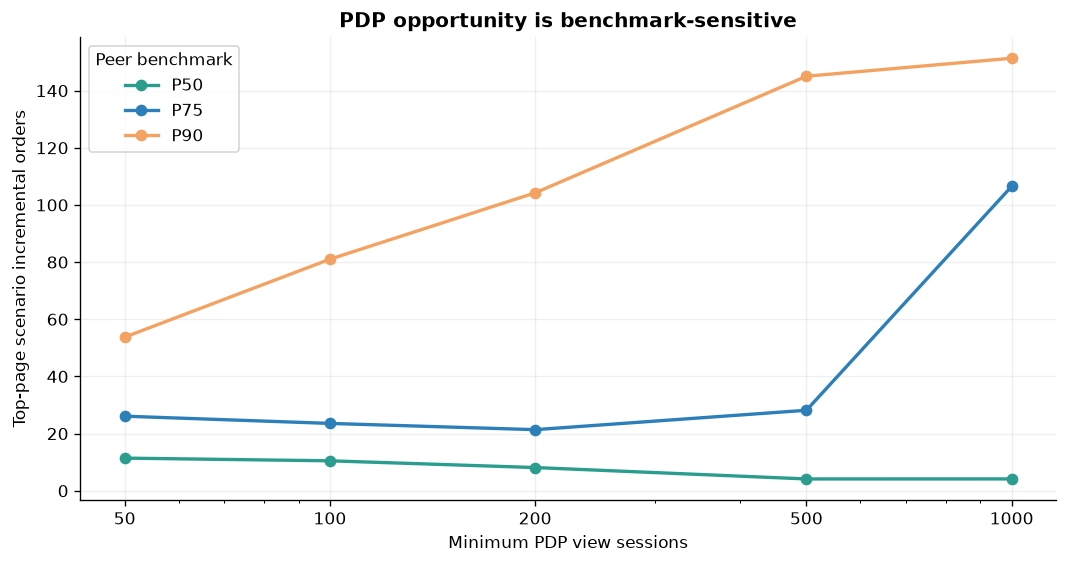

Governed top PDP: Super G Unisex Joggers (21.5 orders, $1,484).
P75 top-page identity across thresholds: Super G Unisex Joggers
Across all tested rules, top-page opportunity ranges from 4.1 to 151.3 orders.


In [8]:
thresholds = [50, 100, 200, 500, 1_000]
benchmark_quantiles = {
    "P50": 0.50,
    "P75": 0.75,
    "P90": 0.90,
}
downstream_rate = float(
    page_opportunity.iloc[0]["scenario_downstream_rate"]
)
average_order_value = float(
    page_opportunity.iloc[0][
        "scenario_average_order_value_usd"
    ]
)
total_page_exposures = page_all["view_sessions"].sum()

sensitivity_rows = []
for threshold in thresholds:
    eligible = page_all[
        page_all["view_sessions"] >= threshold
    ].copy()
    for benchmark_name, quantile in benchmark_quantiles.items():
        benchmark = eligible["view_to_add_rate"].quantile(quantile)
        eligible["scenario_orders"] = (
            eligible["view_sessions"]
            * (benchmark - eligible["view_to_add_rate"]).clip(lower=0)
            * downstream_rate
        )
        top = eligible.loc[eligible["scenario_orders"].idxmax()]
        sensitivity_rows.append(
            {
                "Minimum views": threshold,
                "Benchmark": benchmark_name,
                "Eligible pages": len(eligible),
                "Exposure coverage": (
                    eligible["view_sessions"].sum()
                    / total_page_exposures
                ),
                "Benchmark rate": benchmark,
                "Top page": top["canonical_page_title"],
                "Top page orders": top["scenario_orders"],
                "Top page revenue": (
                    top["scenario_orders"] * average_order_value
                ),
            }
        )

page_sensitivity = pd.DataFrame(sensitivity_rows)
page_sensitivity_display = page_sensitivity.copy()
page_sensitivity_display["Exposure coverage"] = (
    page_sensitivity_display["Exposure coverage"].map(
        lambda value: f"{value:.1%}"
    )
)
page_sensitivity_display["Benchmark rate"] = (
    page_sensitivity_display["Benchmark rate"].map(
        lambda value: f"{value:.2%}"
    )
)
page_sensitivity_display["Top page orders"] = (
    page_sensitivity_display["Top page orders"].map(
        lambda value: f"{value:.1f}"
    )
)
page_sensitivity_display["Top page revenue"] = (
    page_sensitivity_display["Top page revenue"].map(
        lambda value: f"${value:,.0f}"
    )
)
display(page_sensitivity_display)

fig, ax = plt.subplots(figsize=(9, 4.8))
for benchmark_name, color in [
    ("P50", TEAL),
    ("P75", BLUE),
    ("P90", ORANGE),
]:
    frame = page_sensitivity[
        page_sensitivity["Benchmark"] == benchmark_name
    ]
    ax.plot(
        frame["Minimum views"],
        frame["Top page orders"],
        marker="o",
        linewidth=2,
        label=benchmark_name,
        color=color,
    )
ax.set_xscale("log")
ax.set_xticks(thresholds, labels=[str(value) for value in thresholds])
ax.set_xlabel("Minimum PDP view sessions")
ax.set_ylabel("Top-page scenario incremental orders")
ax.set_title("PDP opportunity is benchmark-sensitive")
ax.grid(alpha=0.2)
ax.legend(title="Peer benchmark")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "03_page_sensitivity.png",
    bbox_inches="tight",
)
plt.show()

governed_top = page_opportunity.sort_values(
    "page_opportunity_rank"
).iloc[0]
p75_rows = page_sensitivity[
    page_sensitivity["Benchmark"] == "P75"
]
print(
    "Governed top PDP:",
    governed_top["canonical_page_title"],
    f"({governed_top['scenario_incremental_orders']:.1f} orders, "
    f"${governed_top['scenario_revenue_opportunity_usd']:,.0f}).",
)
print(
    "P75 top-page identity across thresholds:",
    ", ".join(sorted(p75_rows["Top page"].unique())),
)
print(
    "Across all tested rules, top-page opportunity ranges from "
    f"{page_sensitivity['Top page orders'].min():.1f} to "
    f"{page_sensitivity['Top page orders'].max():.1f} orders."
)

## 6. Checkout telemetry and lift scenarios

Two completion definitions form a diagnostic range:

- **strict telemetry path:** purchase after recorded shipping and
  payment events; and
- **any-intermediate ordered path:** clean purchase after ordered
  checkout, even when an intermediate event is absent.

The second is the primary checkout outcome. Follow-up aggregate query
`11_checkout_telemetry_diagnostic.sql` shows that all 941 strict-path
gaps contain shipping at or before the governed checkout start and
payment before purchase. The difference is a sequence/re-entry artifact,
not proven user friction.

,Stage,Sessions,Step conversion,Lost from prior stage
0,begin_checkout,5187,100.00%,0
1,add_shipping_info,2978,57.41%,2209
2,add_payment_info,2360,79.25%,618
3,purchase_after_payment,1550,65.68%,810


,Absolute lift (pp),Incremental orders,Scenario revenue
0,0.2500,13.0,$896
1,0.5000,25.9,"$1,793"
2,1.0000,51.9,"$3,586"
3,2.0000,103.7,"$7,172"
4,3.0000,155.6,"$10,758"
5,5.0000,259.4,"$17,930"


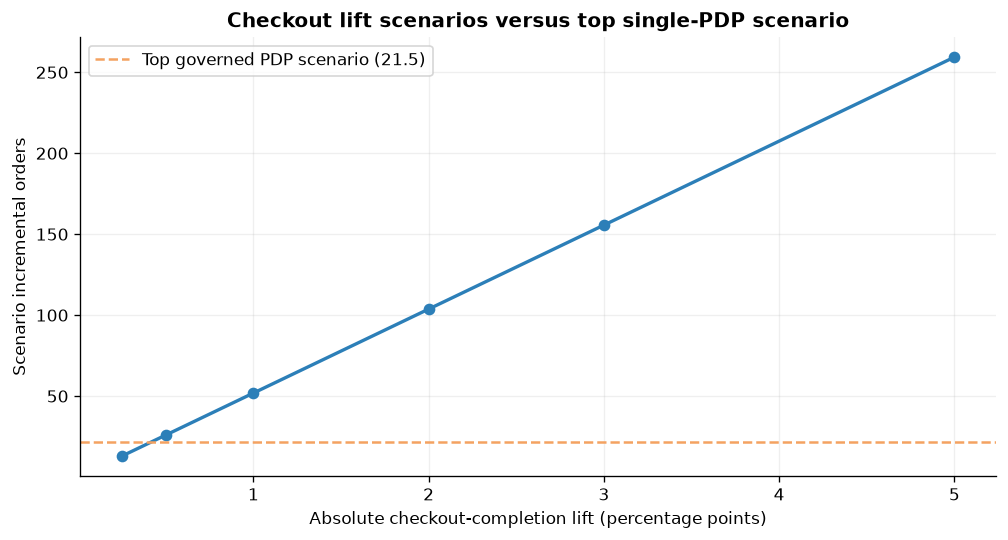

Strict completion: 29.88%; any-intermediate completion: 48.02%.
941 purchase sessions do not contain the full recorded shipping/payment sequence.
Follow-up telemetry diagnostic: every gap purchase has shipping at/before checkout and payment before purchase.


In [9]:
checkout_display = checkout[
    [
        "stage_name",
        "sessions",
        "step_conversion_rate",
        "lost_sessions_from_prior_stage",
    ]
].copy()
checkout_display["step_conversion_rate"] = checkout_display[
    "step_conversion_rate"
].map(lambda value: f"{value:.2%}")
checkout_display = checkout_display.rename(
    columns={
        "stage_name": "Stage",
        "sessions": "Sessions",
        "step_conversion_rate": "Step conversion",
        "lost_sessions_from_prior_stage": "Lost from prior stage",
    }
)
display(checkout_display)

checkout_sessions = int(
    checkout.loc[
        checkout["stage_name"] == "begin_checkout", "sessions"
    ].iloc[0]
)
strict_purchase_sessions = int(
    checkout.loc[
        checkout["stage_name"] == "purchase_after_payment",
        "sessions",
    ].iloc[0]
)
any_path_purchase_sessions = int(
    checkout["purchase_after_checkout_sessions"].iloc[0]
)
telemetry_gap = (
    any_path_purchase_sessions - strict_purchase_sessions
)
strict_rate = strict_purchase_sessions / checkout_sessions
any_path_rate = any_path_purchase_sessions / checkout_sessions

lift_scenarios = pd.DataFrame(
    {"Absolute lift (pp)": [0.25, 0.50, 1.00, 2.00, 3.00, 5.00]}
)
lift_scenarios["Incremental orders"] = (
    checkout_sessions
    * lift_scenarios["Absolute lift (pp)"]
    / 100
)
lift_scenarios["Scenario revenue"] = (
    lift_scenarios["Incremental orders"] * average_order_value
)
lift_display = lift_scenarios.copy()
lift_display["Incremental orders"] = lift_display[
    "Incremental orders"
].map(lambda value: f"{value:.1f}")
lift_display["Scenario revenue"] = lift_display[
    "Scenario revenue"
].map(lambda value: f"${value:,.0f}")
display(lift_display)

top_page_orders = float(
    governed_top["scenario_incremental_orders"]
)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(
    lift_scenarios["Absolute lift (pp)"],
    lift_scenarios["Incremental orders"],
    marker="o",
    color=BLUE,
    linewidth=2,
)
ax.axhline(
    top_page_orders,
    color=ORANGE,
    linestyle="--",
    label=f"Top governed PDP scenario ({top_page_orders:.1f})",
)
ax.set_title("Checkout lift scenarios versus top single-PDP scenario")
ax.set_xlabel("Absolute checkout-completion lift (percentage points)")
ax.set_ylabel("Scenario incremental orders")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "04_checkout_scenarios.png",
    bbox_inches="tight",
)
plt.show()

print(
    f"Strict completion: {strict_rate:.2%}; "
    f"any-intermediate completion: {any_path_rate:.2%}."
)
print(
    f"{telemetry_gap:,} purchase sessions do not contain the full "
    "recorded shipping/payment sequence."
)
print(
    "Follow-up telemetry diagnostic: every gap purchase has shipping "
    "at/before checkout and payment before purchase."
)

## 7. Observed weekly retention

Rates are weighted across only the cohorts with complete follow-up for
each week. The denominator shrinks at later weeks, so the curve is
descriptive context rather than a lifetime-retention estimate.

,Week,Eligible cohort users,Active users,Complete cohorts,Weighted retention
0,0,"255,276","255,276",13,100.00%
1,1,"236,616","8,883",12,3.75%
2,2,"216,400","3,294",11,1.52%
3,3,"195,405","2,109",10,1.08%
4,4,"172,951","1,560",9,0.90%
5,5,"156,658",927,8,0.59%
6,6,"139,650",586,7,0.42%
7,7,"115,440",367,6,0.32%
8,8,"87,889",260,5,0.30%


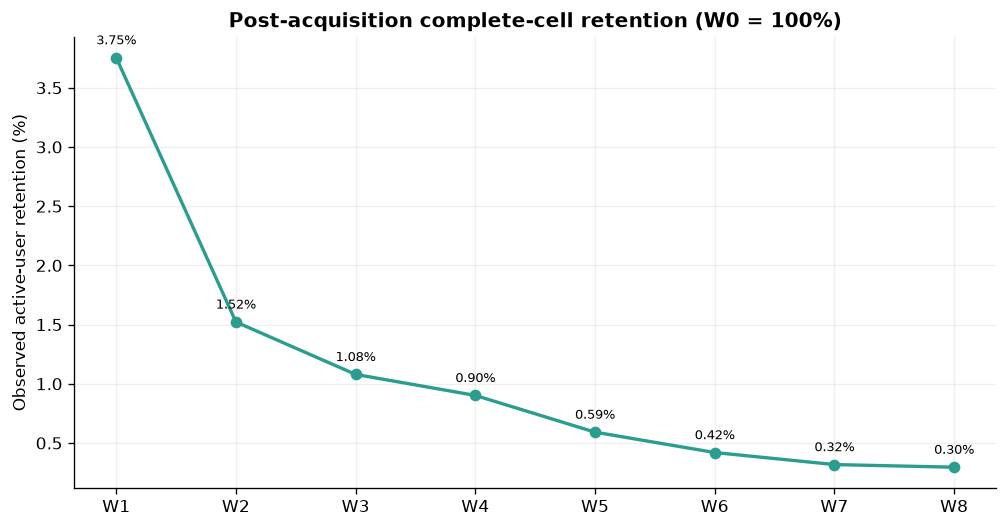

In [10]:
weighted_retention = (
    retention.groupby("retention_week", as_index=False)
    .agg(
        cohort_users=("cohort_users", "sum"),
        active_users=("active_users", "sum"),
        complete_cohorts=("cohort_week", "nunique"),
    )
)
weighted_retention["retention_rate"] = (
    weighted_retention["active_users"]
    / weighted_retention["cohort_users"]
)
retention_display = weighted_retention.copy()
retention_display["retention_rate"] = retention_display[
    "retention_rate"
].map(lambda value: f"{value:.2%}")
for column in ["cohort_users", "active_users"]:
    retention_display[column] = retention_display[column].map(
        lambda value: f"{value:,}"
    )
retention_display = retention_display.rename(
    columns={
        "retention_week": "Week",
        "cohort_users": "Eligible cohort users",
        "active_users": "Active users",
        "complete_cohorts": "Complete cohorts",
        "retention_rate": "Weighted retention",
    }
)
display(retention_display)

retention_plot = weighted_retention[
    weighted_retention["retention_week"] >= 1
]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(
    retention_plot["retention_week"],
    retention_plot["retention_rate"] * 100,
    marker="o",
    color=TEAL,
    linewidth=2,
)
ax.set_xticks(range(1, 9), [f"W{week}" for week in range(1, 9)])
ax.set_ylabel("Observed active-user retention (%)")
ax.set_title(
    "Post-acquisition complete-cell retention (W0 = 100%)"
)
ax.grid(alpha=0.2)
for _, row in retention_plot.iterrows():
    ax.annotate(
        f"{row['retention_rate']:.2%}",
        (row["retention_week"], row["retention_rate"] * 100),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "05_retention_curve.png",
    bbox_inches="tight",
)
plt.show()

## 8. Decision synthesis

The table applies the README decision criteria without pretending that a
subjective score is a measured KPI. “Scenario impact” is not causal.

In [11]:
mobile_purchase = segment_row(
    "Device", "mobile", "purchase_session_conversion"
)
desktop_purchase = segment_row(
    "Device", "desktop", "purchase_session_conversion"
)
returning_purchase = segment_row(
    "User tenure", "Returning", "purchase_session_conversion"
)
new_purchase = segment_row(
    "User tenure", "New", "purchase_session_conversion"
)
half_point_checkout_orders = checkout_sessions * 0.005

decision_matrix = pd.DataFrame(
    [
        {
            "Candidate": "Simplified checkout",
            "Reach": f"{checkout_sessions:,} ordered checkout sessions",
            "Observed evidence": (
                f"{any_path_rate:.2%} same-session completion"
            ),
            "Sensitivity": (
                f"+0.50 pp = {half_point_checkout_orders:.1f} "
                "scenario orders"
            ),
            "Primary caveat": (
                f"{telemetry_gap:,} strict-path gaps are "
                "sequence/re-entry artifacts"
            ),
            "Disposition": "Advance conditionally",
        },
        {
            "Candidate": (
                f"Single PDP: {governed_top['canonical_page_title']}"
            ),
            "Reach": (
                f"{int(governed_top['view_sessions']):,} "
                "session-page views"
            ),
            "Observed evidence": (
                f"{governed_top['view_to_add_rate']:.2%} "
                "view-to-add"
            ),
            "Sensitivity": (
                f"{page_sensitivity['Top page orders'].min():.1f}–"
                f"{page_sensitivity['Top page orders'].max():.1f} "
                "top-page scenario orders"
            ),
            "Primary caveat": (
                "Benchmark-sensitive and page values are non-additive"
            ),
            "Disposition": "Retain as secondary",
        },
        {
            "Candidate": "Mobile-specific redesign",
            "Reach": (
                f"{int(mobile_purchase['denominator_sessions']):,} "
                "mobile sessions"
            ),
            "Observed evidence": (
                f"{mobile_purchase['conversion_rate']:.2%} mobile "
                f"vs {desktop_purchase['conversion_rate']:.2%} desktop"
            ),
            "Sensitivity": "No observed mobile deficit",
            "Primary caveat": "Raw association; device mix is uncontrolled",
            "Disposition": "Do not prioritize",
        },
        {
            "Candidate": "New-user experience",
            "Reach": (
                f"{int(new_purchase['denominator_sessions']):,} "
                "New sessions"
            ),
            "Observed evidence": (
                f"{returning_purchase['conversion_rate']:.2%} "
                "Returning vs "
                f"{new_purchase['conversion_rate']:.2%} New"
            ),
            "Sensitivity": "Large, stable descriptive split",
            "Primary caveat": (
                "Tenure is not itself a product intervention"
            ),
            "Disposition": "Use as diagnostic lens",
        },
    ]
)
display(decision_matrix)

decision_checks = pd.DataFrame(
    {
        "Check": [
            "Flagged-date exclusion changes purchase conversion < 5 bps",
            "Mobile purchase conversion is not below desktop",
            "Returning purchase conversion exceeds New",
            "P75 top PDP is stable across tested traffic thresholds",
            "+0.50 pp checkout scenario exceeds governed top PDP scenario",
        ],
        "Pass": [
            abs(
                (filtered_purchase_rate - full_purchase_rate) * 10_000
            )
            < 5,
            mobile_purchase["conversion_rate"]
            >= desktop_purchase["conversion_rate"],
            returning_purchase["conversion_rate"]
            > new_purchase["conversion_rate"],
            p75_rows["Top page"].nunique() == 1,
            half_point_checkout_orders > top_page_orders,
        ],
    }
)
assert decision_checks["Pass"].all()
display(decision_checks)

,Candidate,Reach,Observed evidence,Sensitivity,Primary caveat,Disposition
0,Simplified checkout,"5,187 ordered checkout sessions",48.02% same-session completion,+0.50 pp = 25.9 scenario orders,941 strict-path gaps are sequence/re-entry artifacts,Advance conditionally
1,Single PDP: Super G Unisex Joggers,"3,830 session-page views",1.20% view-to-add,4.1–151.3 top-page scenario orders,Benchmark-sensitive and page values are non-additive,Retain as secondary
2,Mobile-specific redesign,"143,185 mobile sessions",1.15% mobile vs 1.10% desktop,No observed mobile deficit,Raw association; device mix is uncontrolled,Do not prioritize
3,New-user experience,"261,238 New sessions",2.55% Returning vs 0.57% New,"Large, stable descriptive split",Tenure is not itself a product intervention,Use as diagnostic lens


,Check,Pass
0,Flagged-date exclusion changes purchase conversion < 5 bps,True
1,Mobile purchase conversion is not below desktop,True
2,Returning purchase conversion exceeds New,True
3,P75 top PDP is stable across tested traffic thresholds,True
4,+0.50 pp checkout scenario exceeds governed top PDP scenario,True


In [12]:
display(
    Markdown(
        f"""
        ## Provisional product direction

        **Advance a simplified checkout intervention into experiment
        design, conditional on experiment-specific telemetry and MDE
        approval.**

        Why this moves forward:

        - checkout has {checkout_sessions:,} eligible ordered sessions;
        - its any-intermediate same-session completion is
          {any_path_rate:.2%};
        - a +0.50 percentage-point scenario equals
          {half_point_checkout_orders:.1f} incremental orders, already
          above the governed top single-PDP scenario of
          {top_page_orders:.1f}; and
        - the initial mobile-friction hypothesis is not supported.

        Conditions before launch:

        1. log one dedicated sticky experiment exposure instead of
           relying on repeated `begin_checkout` events;
        2. keep clean purchase after first eligible checkout as the
           primary outcome;
        3. randomize by pseudonymous user with sticky 50/50 assignment;
        4. validate payment-error, refund, and checkout-time guardrails;
        5. preregister the MDE and sample size; and
        6. treat New-versus-Returning interaction analysis as
           secondary/exploratory.

        This is a prioritization decision for the next experiment, not
        evidence that a simplified checkout has already caused an
        improvement.
        """
    )
)


        ## Provisional product direction

        **Advance a simplified checkout intervention into experiment
        design, conditional on experiment-specific telemetry and MDE
        approval.**

        Why this moves forward:

        - checkout has 5,187 eligible ordered sessions;
        - its any-intermediate same-session completion is
          48.02%;
        - a +0.50 percentage-point scenario equals
          25.9 incremental orders, already
          above the governed top single-PDP scenario of
          21.5; and
        - the initial mobile-friction hypothesis is not supported.

        Conditions before launch:

        1. log one dedicated sticky experiment exposure instead of
           relying on repeated `begin_checkout` events;
        2. keep clean purchase after first eligible checkout as the
           primary outcome;
        3. randomize by pseudonymous user with sticky 50/50 assignment;
        4. validate payment-error, refund, and checkout-time guardrails;
        5. preregister the MDE and sample size; and
        6. treat New-versus-Returning interaction analysis as
           secondary/exploratory.

        This is a prioritization decision for the next experiment, not
        evidence that a simplified checkout has already caused an
        improvement.
        

## Reproducibility notes

- Source metrics come from the governed BigQuery marts.
- Every input is an aggregate CSV under the Git-ignored
  `data/interim/query_results/` directory.
- Figures are generated under `notebooks/figures/`.
- No simulated data are used in this notebook.
- The companion `02_ab_test_design_and_simulation.ipynb` preselects the
  planning MDE, computes sample size and fixed-N MDE, and demonstrates
  the analysis on visibly labeled, seeded simulated experiment data.